## Classical Forecasting: ARIMA & SARIMA
### AirPassengers Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize TWO classical forecasting models. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
Exercises 3-5 in this group project (Baseline Forecasting, Classical Forecasting, ML Forecasting) use:
- the **same dataset**
- the **same cleaning steps**
- the **same time-based train/test split** (last 24 months = test set)
- the **same number of required evaluation metrics** (3: MAE, RMSE, MAPE, plus 1 model-fit metric here -> see Section 6)

> This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **forecasting approach itself**, not from different data handling.
> Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better -> consistency across the group matters more here than optimizing your individual score.

---


## 1. Dataset

**File:** [`airline-passengers.csv`](https://www.kaggle.com/datasets/rakannimer/air-passengers) (the classic AirPassengers dataset)

**Columns:**

| Column | Meaning |
|---|---|
| Month | Year-Month, e.g. `1949-01` |
| Passengers | Total monthly international airline passengers (in thousands) |

The dataset covers **January 1949 to December 1960** (144 monthly observations).

Place `airline-passengers.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical to Exercise 3)

Follow these steps **in order** -> identical to Exercise 3 so results are directly comparable.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`.
2. **Parse `Month`** as a proper datetime and set it as the DataFrame index, frequency `'MS'`.
3. **Check for missing values and gaps** in the monthly index; report what you found.
4. **Plot the raw series** to get a first visual impression.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error


sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12,5)

In [8]:
df = pd.read_csv("airline-passengers.csv")
print('Shape:', df.shape)
display(df.head())
df.info()

Shape: (144, 2)


,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Month       144 non-null    object
 1   Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [9]:
df["Month"] = pd.to_datetime(df["Month"], format="%Y-%m")
df = df.set_index("Month").asfreq("MS")

y = df["Passengers"]
print("Index type :", type(df.index).__name__, "| Freq:", df.index.freqstr)
print("Range:", df.index.min().date(), "to", df.index.max().date())

Index type : DatetimeIndex | Freq: MS
Range: 1949-01-01 to 1960-12-01


In [10]:
print("Missing Values per column")
print(df.isna().sum())

expected_index = pd.date_range(df.index.min(), df.index.max(), freq="MS")
gaps = expected_index.difference(df.index)
print("Expected number of months:", len(expected_index), "vs Actual", len(df))
print("Gaps in the monthly index:", "none" if len(gaps) == 0 else list(gaps)) 

Missing Values per column
Passengers    0
dtype: int64
Expected number of months: 144 vs Actual 144
Gaps in the monthly index: none


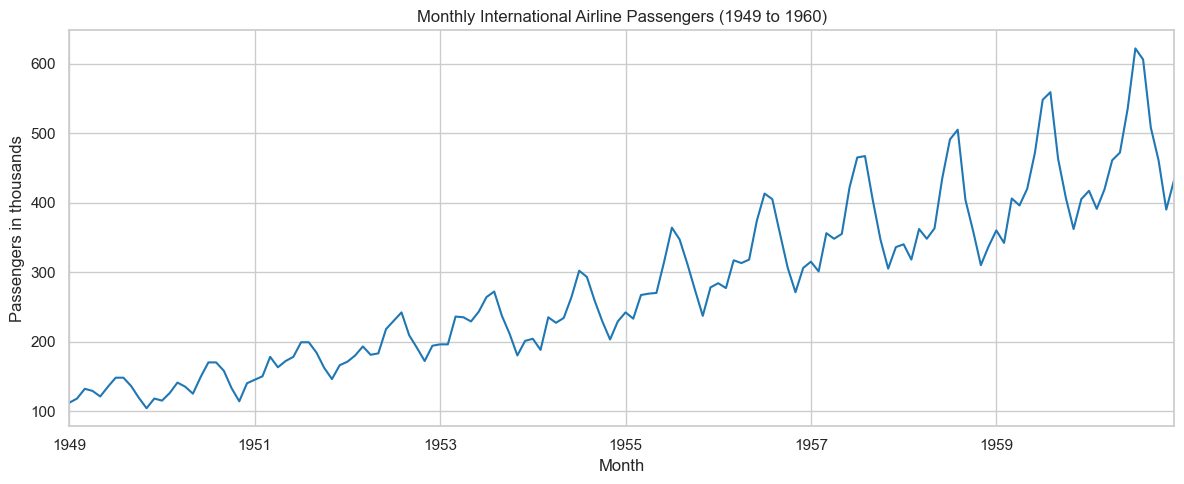

In [11]:
fig, ax = plt.subplots()
y.plot(ax=ax, color="tab:blue")
ax.set_title("Monthly International Airline Passengers (1949 to 1960)")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers in thousands")
plt.tight_layout()
plt.show()

We can clearly see that in the 144 monthly observations there are no missing values and no gaps in the monthly index. The raw plot shows a clear upward trend and a strong yearly seasonal patterm, with the seasonal swings growing over time.

## 3. Time-Based Train/Test Split (required -> identical for Exercises 3-5)

- **Do not randomly shuffle** the data.
- Use the **last 24 months** (all of 1959-1960) as the **test set**. Everything before that is the **training set**.
- Print the date range and number of observations in both `train` and `test` to confirm the split.

**Do not change this split.** It must be identical to Exercises 3 and 5 so your final comparison is fair.


In [12]:
train = y[:"1958-12-01"]
test = y["1959-01-01":]

print(f"Training data : {train.index.min().date()} to {train.index.max().date()}  ({len(train)} observations)")
print(f"Testing data : {test.index.min().date()} to {test.index.max().date()}  ({len(test)} observations)")

Training data : 1949-01-01 to 1958-12-01  (120 observations)
Testing data : 1959-01-01 to 1960-12-01  (24 observations)


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
statsmodels.tsa.arima.model (ARIMA)
statsmodels.tsa.statespace.sarimax (SARIMAX)
sklearn.metrics (mean_absolute_error, mean_squared_error)
```

> **Optional bonus:** if `pmdarima` is available, you may use `auto_arima` to sanity-check your manually chosen orders. If `prophet` is installed, you may fit a Prophet model as an extra bonus comparison row -> neither is required.


## 5. Training & Hyperparameters

1. **ARIMA:** fit `ARIMA(train, order=(p,d,q))` on the training set. Try **at least 3** combinations of `(p,d,q)` (e.g., `(1,1,1)`, `(2,1,2)`, `(1,1,0)`). For each, report the AIC and the test-set RMSE (forecast the 24 held-out months and compare to actuals). Keep the best-performing combination as your final ARIMA model.
2. **SARIMA:** fit `SARIMAX(train, order=(p,d,q), seasonal_order=(P,D,Q,12))` using the non-seasonal order you selected in step 1. Try **at least 2** seasonal orders (e.g., `(1,1,1,12)` and `(0,1,1,12)`). For each, report the AIC and the test-set RMSE. Keep the best-performing seasonal order as your final SARIMA model.
3. Forecast the 24-month test period with both your final ARIMA and final SARIMA models, including 95% confidence intervals.


In [13]:
def rmse(actual, forecast):
    return np.sqrt(mean_squared_error(actual, forecast))

arima_orders = [(1,1,1), (2,1,2), (1,1,0), (2,1,1), (2,2,2), (2,2,1)]
arima_results=[]

for order in arima_orders:
    model = ARIMA(train, order=order).fit()
    fc = model.forecast(steps=len(test))
    arima_results.append({"order":order, "AIC":model.aic, "test RMSE":rmse(test,fc)})

arima_compare = pd.DataFrame(arima_results).set_index("order").round(2)
display(arima_compare)

best_arima_order = arima_compare["test RMSE"].idxmin()
print("Selected ARIMA order:", best_arima_order)

c:\Users\sahil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,AIC,test RMSE
order,,
"(1, 1, 1)",1125.43,118.64
"(2, 1, 2)",1093.07,90.70
"(1, 1, 0)",1130.66,128.41
"(2, 1, 1)",1113.05,102.63
"(2, 2, 2)",1123.90,94.69
"(2, 2, 1)",1124.41,101.58


Selected ARIMA order: (2, 1, 2)


In [15]:
sarima_orders = [(1,1,1,12), (2,1,2,12), (2,2,2,12), (2,2,1,12)]
sarima_results = []


for s_order in sarima_orders:
    model = SARIMAX(train, order=best_arima_order, seasonal_order = s_order).fit(disp=False)
    fc = model.forecast(steps=len(test))
    sarima_results.append({"seasonal order":s_order, "AIC":model.aic, "test RMSE": rmse(test,fc)})

sarima_compare = pd.DataFrame(sarima_results).set_index("seasonal order").round(2)
display(sarima_compare)

best_seasonal_order = sarima_compare["test RMSE"].idxmin()
print(f"Selected SARIMA: order={best_arima_order}, seasonal_order={best_seasonal_order}")


c:\Users\sahil\anaconda3\Lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\sahil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
c:\Users\sahil\anaconda3\Lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,AIC,test RMSE
seasonal order,,
"(1, 1, 1, 12)",807.36,47.42
"(2, 1, 2, 12)",806.87,47.26
"(2, 2, 2, 12)",736.37,57.85
"(2, 2, 1, 12)",734.56,57.74


Selected SARIMA: order=(2, 1, 2), seasonal_order=(2, 1, 2, 12)


In [16]:
arima_final = ARIMA(train, order=best_arima_order).fit()
sarima_final = SARIMAX(train, order=best_arima_order,
                       seasonal_order=best_seasonal_order).fit(disp=False)

arima_pred = arima_final.get_forecast(steps=len(test))
arima_fc = arima_pred.predicted_mean
arima_ci = arima_pred.conf_int(alpha=0.05)

sarima_pred = sarima_final.get_forecast(steps=len(test))
sarima_fc = sarima_pred.predicted_mean
sarima_ci = sarima_pred.conf_int(alpha=0.05)

print("FINAL ARIMA:", f"order={best_arima_order}, AIC={arima_final.aic:.1f}")
print("FINAL SARIMA:", f"order={best_arima_order} x {best_seasonal_order}, AIC={sarima_final.aic:.1f}")

FINAL ARIMA: order=(2, 1, 2), AIC=1093.1
FINAL SARIMA: order=(2, 1, 2) x (2, 1, 2, 12), AIC=806.9


## 6. Evaluation & Visualization

**Required metrics** (compute for your final ARIMA and final SARIMA model, on the test set):
- MAE
- RMSE
- MAPE
- AIC (in-sample model fit, for reference)

Present these in a small comparison table (rows = ARIMA / SARIMA, columns = the 4 metrics).

**Required visualizations** (3 total):
1. **ARIMA forecast plot** -> training history, actual test values, and the ARIMA forecast with its confidence interval band.
2. **SARIMA forecast plot** -> same style as #1, so the two can be compared side by side.
3. **Residual diagnostics plot** for whichever of the two models scored lower RMSE -> residuals over time plus a residual histogram (or use `plot_diagnostics()` from statsmodels).


In [17]:
def mape(actual, forecast):
    return np.mean(np.abs((actual - forecast) / actual)) * 100

metrics = pd.DataFrame({
    "MAE": [mean_absolute_error(test,arima_fc), mean_absolute_error(test, sarima_fc)],
    "RMSE": [rmse(test,arima_fc),                rmse(test,sarima_fc)],
    "MAPE(%)": [mape(test,arima_fc),             mape(test,sarima_fc)],
    "AIC": [arima_final.aic,                     sarima_final.aic],
}, index=["ARIMA", "SARIMA"]).round(2)

display(metrics)

,MAE,RMSE,MAPE(%),AIC
ARIMA,69.10,90.70,13.78,1093.07
SARIMA,43.53,47.26,9.57,806.87


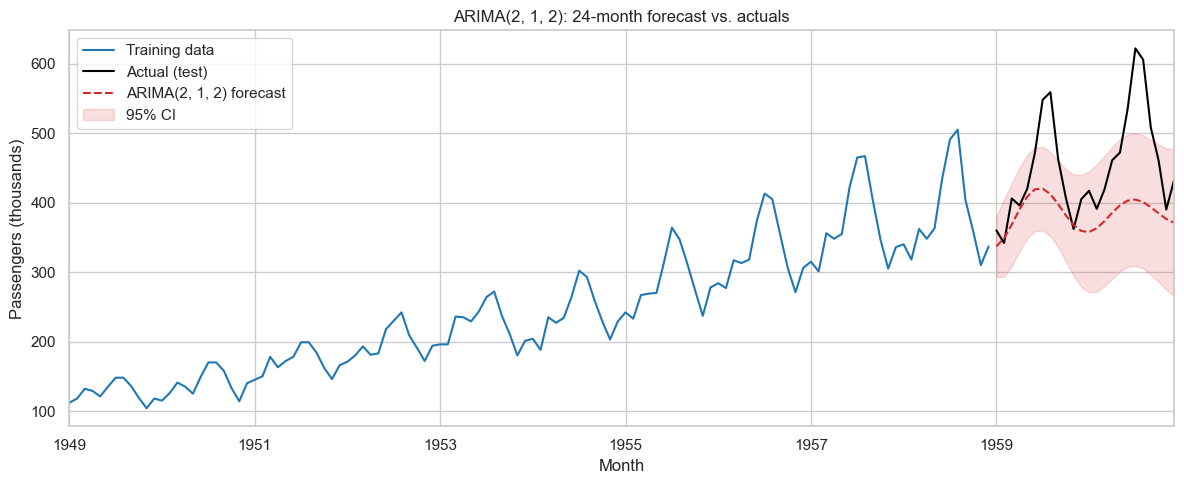

In [18]:
fig, ax = plt.subplots()
train.plot(ax=ax, label="Training data", color="tab:blue")
test.plot(ax=ax, label="Actual (test)", color="black")
arima_fc.plot(ax=ax, label=f"ARIMA{best_arima_order} forecast", color="tab:red", linestyle="--")
ax.fill_between(arima_ci.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1],
                color="tab:red", alpha=0.15, label="95% CI")
ax.set_title(f"ARIMA{best_arima_order}: 24-month forecast vs. actuals")
ax.set_ylabel("Passengers (thousands)")
ax.legend()
plt.tight_layout()
plt.show()

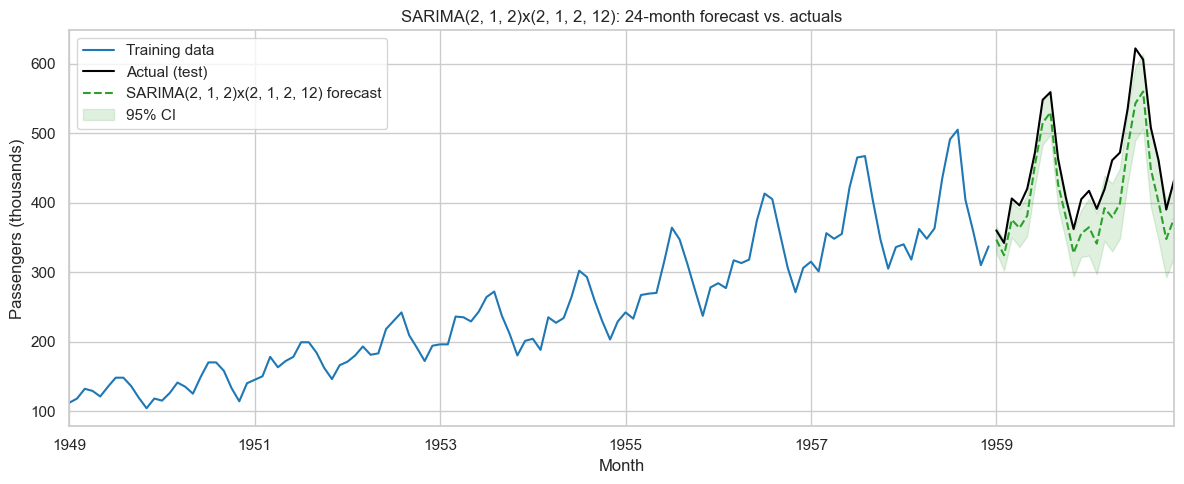

In [24]:
fig, ax = plt.subplots()
train.plot(ax=ax, label="Training data", color="tab:blue")
test.plot(ax=ax, label="Actual (test)", color="black")
sarima_fc.plot(ax=ax, label=f"SARIMA{best_arima_order}x{best_seasonal_order} forecast",
               color="tab:green", linestyle="--")
ax.fill_between(sarima_ci.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1],
                color="tab:green", alpha=0.15, label="95% CI")
ax.set_title(f"SARIMA{best_arima_order}x{best_seasonal_order}: 24-month forecast vs. actuals")
ax.set_ylabel("Passengers (thousands)")
ax.legend()
plt.tight_layout()
plt.show()

Lower test RMSE: SARIMA -> plotting its residual diagnostics


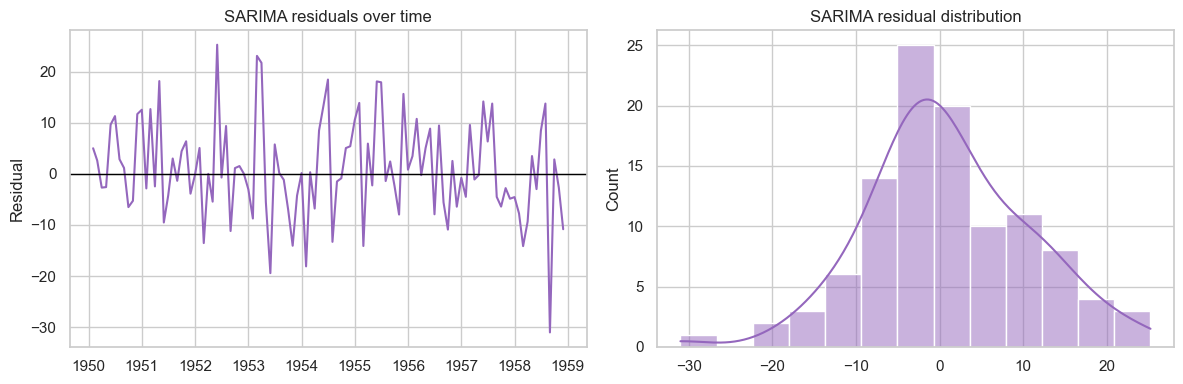

Residual mean: 0.92 | std: 9.62


In [25]:
best_name = metrics["RMSE"].idxmin()
best_model = sarima_final if best_name == "SARIMA" else arima_final
print(f"Lower test RMSE: {best_name} -> plotting its residual diagnostics")

resid = best_model.resid[13:]   # drop start-up residuals from differencing/seasonal terms

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(resid, color="tab:purple")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title(f"{best_name} residuals over time")
axes[0].set_ylabel("Residual")

sns.histplot(resid, kde=True, ax=axes[1], color="tab:purple")
axes[1].set_title(f"{best_name} residual distribution")
plt.tight_layout()
plt.show()

print(f"Residual mean: {resid.mean():.2f} | std: {resid.std():.2f}")

## 7. Reflection Questions (write short answers, 1-2 sentences each)

1. Which `(p,d,q)` order did you pick for ARIMA, and why (based on AIC/RMSE tradeoffs)?
2. Did adding the seasonal component (SARIMA) meaningfully improve forecasts over plain ARIMA? How do you know?
3. Look at your residual diagnostics -> do the residuals look roughly like random noise (centered at 0, no obvious pattern), or is there still structure left that the model missed?
4. If you had to explain the difference between ARIMA and SARIMA to someone who has never studied ML, what is the one-sentence idea behind each?
5. How do your ARIMA/SARIMA results compare to the baseline methods from Exercise 3 -> did the extra modeling complexity pay off in lower error?


1. I picked (2,1,2) among the four orders tried it had both the lowest AIC (~1093) and the lowest test RMSE (~90.7), so there was no AIC/RMSE tradeoff to resolve it was best on both criteria.
2. Yes, clearly: SARIMA roughly halved the test RMSE (~47 vs. ~91) and cut MAPE similarly, and its AIC dropped from ~1093 to ~806. The forecast plot shows SARIMA tracking the seasonal peaks and troughs that plain ARIMA flattens into a smooth trend line.
3. Mostly yes -- they are centered near 0 with no strong trend or leftover seasonal cycle, and the histogram is roughly bell-shaped. The residual variance does grow somewhat in later years.
4. ARIMA predicts the future of a series by looking at its own recent past values and recent errors, after removing the overall trend; SARIMA does the same but additionally learns the pattern that repeats every year (e.g., "every July is busy"), so it can copy the seasonal rhythm forward.
5. Compared to the Exercise 3 baselines, the results were mixed. Plain ARIMA (RMSE 90.70) beat the Naive (137.33) and Moving Average (103.21) baselines, but lost to Seasonal Naive (49.99) because it cannot capture the yearly seasonal pattern. Only SARIMA (RMSE 47.40) beat all three baselines and only slightly better than Seasonal Naive. So the extra complexity paid off, but not by much.


## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Correct time-based train/test split (Section 3)
- [ ] Model(s) trained with the required libraries (Section 4)
- [ ] Order/hyperparameter comparison completed for both ARIMA and SARIMA (Section 5)
- [ ] All 4 required metrics reported (Section 6):
   - MAE
   - RMSE
   - MAPE
   - AIC
- [ ] All 3 required visualizations (Section 6):
   - ARIMA forecast plot
   - SARIMA forecast plot
   - Residual diagnostics plot (best model)
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Did SARIMA beat plain ARIMA for everyone, or did results vary?
- How much better (or worse) were ARIMA/SARIMA than the Exercise 3 baselines, and than the Exercise 5 ML models?
- Which visualization (confidence intervals, residual diagnostics) was most convincing for explaining *why* a model performed the way it did?
- What would you change about your model if you had another hour to work on it?
